# Week 9: Gradient Boosting

Applying Gradient Boosting explores learning rate, number of estimators, tree depth, and regularization to understand how these parameters affect model accuracy and overfitting. Hyperparameter tuning will be used to identify effective model configurations and compare results across the datasets.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

pd.set_option("display.max_columns", None)

In [8]:
df1 = pd.read_csv("digital_marketing_campaign_dataset.csv")
df2 = pd.read_csv("marketing_and_product_performance.csv")
df3 = pd.read_csv("companies_clean_734.csv")

print("Digital Marketing Campaign:", df1.shape)
print("Marketing and Product Performance:", df2.shape)
print("Synthetic B2B CRM & Marketing Dataset:", df3.shape)

Digital Marketing Campaign: (8000, 20)
Marketing and Product Performance: (10000, 17)
Synthetic B2B CRM & Marketing Dataset: (734, 19)


## Dataset 1: Digital Marketing Campaign

The target variable is Conversion, representing whether a customer converted. Gradient Boosting will be used to classify customers based on AdSpend, ClickThroughRate, WebsiteVisits, TimeOnSite, and EmailClicks. The dataset will be divided into training and testing sets using an 80/20 split. Since Gradient Boosting uses decision trees, feature scaling is not required.

In [9]:
features1 = ["AdSpend", "ClickThroughRate", "WebsiteVisits", "TimeOnSite", "EmailClicks"]

X1 = df1[features1]
y1 = df1["Conversion"]
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X1, y1, test_size=0.2, random_state=42, stratify=y1
)

print("Training:", X1_train.shape)
print("Testing:", X1_test.shape)
print("\nTarget Distribution:")
print(y1.value_counts())

Training: (6400, 5)
Testing: (1600, 5)

Target Distribution:
Conversion
1    7012
0     988
Name: count, dtype: int64


### Initial Gradient Boosting Model

Gradient Boosting classifier would be built with 100 estimators, 0.1 learning rate, and 3 maximum tree depth. The classifier is built by creating decision trees one-by-one where each tree is used for compensating mistakes made by previous trees. Accuracy, Precision, Recall, F1-score and ROC-AUC would be used as performance measures.

In [10]:
gb1 = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb1.fit(X1_train, y1_train)
y1_pred = gb1.predict(X1_test)
y1_prob = gb1.predict_proba(X1_test)[:, 1]

print("Gradient Boosting (100 Estimators, LR=0.1, Depth=3)")
print("Accuracy:", round(accuracy_score(y1_test, y1_pred), 4))
print("Precision:", round(precision_score(y1_test, y1_pred), 4))
print("Recall:", round(recall_score(y1_test, y1_pred), 4))
print("F1 Score:", round(f1_score(y1_test, y1_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, y1_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y1_test, y1_pred))

Gradient Boosting (100 Estimators, LR=0.1, Depth=3)
Accuracy: 0.8819
Precision: 0.8915
Recall: 0.985
F1 Score: 0.936
ROC-AUC: 0.7311

Confusion Matrix:
[[  30  168]
 [  21 1381]]


The first Gradient Boosting model had an accuracy of 88.19% with a ROC-AUC value of 0.7311. From the confusion matrix, it was observed that there were 1,381 successful conversions and 30 unsuccessful conversions classified successfully by the model. As compared to the optimized KNN model developed in Week 8, the Gradient Boosting performed a bit better but still was biased towards conversions.

### Learning Rate and Number of Estimators

Various values for learning rate and number of estimators will be tried out in order to determine their impact on the performance of gradient boosting. The smaller the learning rate, the better the algorithm can learn incrementally. The higher the number of estimators, the more chances the algorithm has to fix its mistakes.

In [11]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
estimators = [50, 100, 200]

lr_results1 = []

for lr in learning_rates:
    for n in estimators:
        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=lr,
            max_depth=3,
            random_state=42
        )

        model.fit(X1_train, y1_train)
        train_prob = model.predict_proba(X1_train)[:, 1]
        test_prob = model.predict_proba(X1_test)[:, 1]

        lr_results1.append({
            "Learning Rate": lr,
            "Estimators": n,
            "Train ROC-AUC": roc_auc_score(y1_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y1_test, test_prob)
        })

lr_results1_df = pd.DataFrame(lr_results1)
print(lr_results1_df.round(4).to_string(index=False))

 Learning Rate  Estimators  Train ROC-AUC  Test ROC-AUC
          0.01          50         0.7621        0.7201
          0.01         100         0.7705        0.7210
          0.01         200         0.7834        0.7268
          0.05          50         0.7896        0.7280
          0.05         100         0.8045        0.7240
          0.05         200         0.8276        0.7260
          0.10          50         0.8025        0.7330
          0.10         100         0.8292        0.7311
          0.10         200         0.8670        0.7281
          0.20          50         0.8238        0.7296
          0.20         100         0.8668        0.7289
          0.20         200         0.9180        0.7193


Adjustment of learning rate and number of estimators showed a trade-off between the complexity of the model and generalization. The best testing ROC-AUC was 0.7330 where the learning rate was 0.10 and there were 50 estimators. With a learning rate of 0.20 and 200 estimators, training ROC-AUC was 0.9180 and testing ROC-AUC was 0.7193 showing an over-fitting case. In general, the increase in the number of trees and learning rate had no impact on testing results.

### Tree Depth Comparison

In [12]:
depth_values = [1, 2, 3, 4, 5]
depth_results1 = []

for depth in depth_values:
    model = GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.1,
        max_depth=depth,
        random_state=42
    )

    model.fit(X1_train, y1_train)
    train_prob = model.predict_proba(X1_train)[:, 1]
    test_prob = model.predict_proba(X1_test)[:, 1]

    depth_results1.append({
        "Max Depth": depth,
        "Train ROC-AUC": roc_auc_score(y1_train, train_prob),
        "Test ROC-AUC": roc_auc_score(y1_test, test_prob)
    })

depth_results1_df = pd.DataFrame(depth_results1)
print(depth_results1_df.round(4).to_string(index=False))

 Max Depth  Train ROC-AUC  Test ROC-AUC
         1         0.7559        0.7383
         2         0.7757        0.7317
         3         0.8025        0.7330
         4         0.8429        0.7267
         5         0.8911        0.7260


Tree depth had a noticeable effect on Gradient Boosting performance. A maximum depth of 1 achieved the highest testing ROC-AUC of 0.7383, while deeper trees produced progressively higher training scores without improving testing performance. At depth 5, training ROC-AUC increased to 0.8911, but testing ROC-AUC decreased to 0.7260. These results suggest that shallow trees generalized better and that increasing tree depth introduced overfitting.

### Regularization Comparison

In [13]:
leaf_values = [1, 5, 10]
subsample_values = [0.7, 0.85, 1.0]

reg_results1 = []

for leaf in leaf_values:
    for sample in subsample_values:
        model = GradientBoostingClassifier(
            n_estimators=50,
            learning_rate=0.1,
            max_depth=1,
            min_samples_leaf=leaf,
            subsample=sample,
            random_state=42
        )

        model.fit(X1_train, y1_train)
        train_prob = model.predict_proba(X1_train)[:, 1]
        test_prob = model.predict_proba(X1_test)[:, 1]
        reg_results1.append({
            "Min Leaf": leaf,
            "Subsample": sample,
            "Train ROC-AUC": roc_auc_score(y1_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y1_test, test_prob)
        })

reg_results1_df = pd.DataFrame(reg_results1)
print(reg_results1_df.round(4).to_string(index=False))

 Min Leaf  Subsample  Train ROC-AUC  Test ROC-AUC
        1       0.70         0.7580        0.7369
        1       0.85         0.7564        0.7369
        1       1.00         0.7559        0.7383
        5       0.70         0.7580        0.7369
        5       0.85         0.7564        0.7369
        5       1.00         0.7559        0.7383
       10       0.70         0.7580        0.7369
       10       0.85         0.7564        0.7369
       10       1.00         0.7559        0.7383


Regularization produced only minor changes in Gradient Boosting performance. Changing the minimum leaf size from 1 to 10 had no effect on the results, while subsampling slightly reduced testing ROC-AUC. The highest testing ROC-AUC of 0.7383 was achieved with a subsample of 1.0. These findings suggest that the shallow trees already limited model complexity, reducing the additional benefit of regularization.

### Gradient Boosting Hyperparameter Tuning

In [14]:
param_grid1 = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 5],
    "subsample": [0.85, 1.0]
}

grid1 = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid1,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid1.fit(X1_train, y1_train)
print("Best Parameters:", grid1.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid1.best_score_, 4))

best_gb1 = grid1.best_estimator_
y1_pred_tuned = best_gb1.predict(X1_test)
y1_prob_tuned = best_gb1.predict_proba(X1_test)[:, 1]

print("\nTuned Gradient Boosting Testing Results:")
print("Accuracy:", round(accuracy_score(y1_test, y1_pred_tuned), 4))
print("Precision:", round(precision_score(y1_test, y1_pred_tuned), 4))
print("Recall:", round(recall_score(y1_test, y1_pred_tuned), 4))
print("F1 Score:", round(f1_score(y1_test, y1_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y1_test, y1_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y1_test, y1_pred_tuned))

Best Parameters: {'learning_rate': 0.05, 'max_depth': 1, 'min_samples_leaf': 5, 'n_estimators': 200, 'subsample': 0.85}
Best Cross-Validation ROC-AUC: 0.75

Tuned Gradient Boosting Testing Results:
Accuracy: 0.8762
Precision: 0.8772
Recall: 0.9986
F1 Score: 0.934
ROC-AUC: 0.7333

Confusion Matrix:
[[   2  196]
 [   2 1400]]


The optimal values for the learning rate, number of estimators, maximum depth, minimum samples leaf, and the sampling fraction using GridSearchCV were found to be 0.05, 200, 1, 5, and 0.85 respectively. Using these parameters, the new model yielded an ROC-AUC score of 0.7500 on cross-validation and 0.7333 on testing, a slight improvement from the ROC-AUC of the first model, which was 0.7311. Nevertheless, there was a decrease in accuracy to 87.62% and the model was able to predict just two cases of non-conversion.

In [31]:
print("Dataset 1 Classification Report:")
print(classification_report(y1_test, y1_pred_tuned))

Dataset 1 Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.01      0.02       198
           1       0.88      1.00      0.93      1402

    accuracy                           0.88      1600
   macro avg       0.69      0.50      0.48      1600
weighted avg       0.83      0.88      0.82      1600



Despite the high accuracy rate of 88%, the gradient boosting model exhibited considerable class imbalance. The recall for Class 1 was 1.00, whereas that of Class 0 was 0.01, which means that almost all non-converting clients were incorrectly classified. As 87.6% of the customers were in Class 1, the accuracy score overstates the performance of the model.

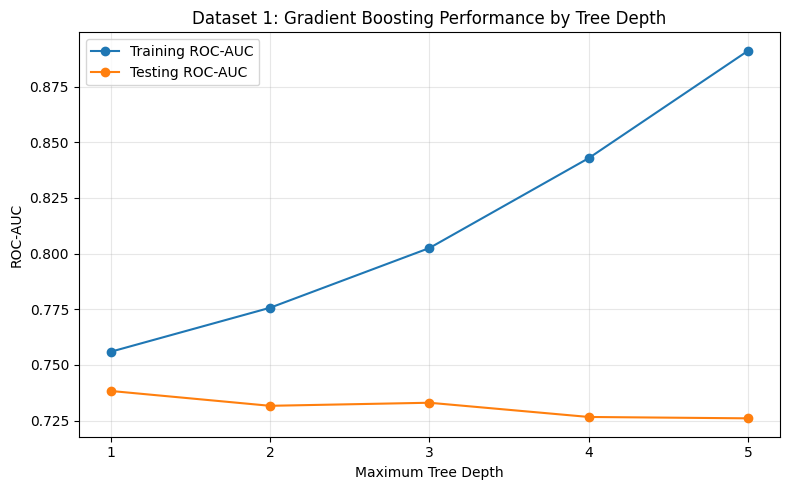

In [15]:
plt.figure(figsize=(8, 5))

plt.plot(
    depth_results1_df["Max Depth"],
    depth_results1_df["Train ROC-AUC"],
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    depth_results1_df["Max Depth"],
    depth_results1_df["Test ROC-AUC"],
    marker="o",
    label="Testing ROC-AUC"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC-AUC")
plt.title("Dataset 1: Gradient Boosting Performance by Tree Depth")
plt.xticks(depth_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Dataset 1 Conclusion

The Gradient Boosting algorithm performed moderately well on the Digital Marketing Campaign dataset. While the original model performed at 88.19% accuracy and an ROC-AUC of 0.7311, the optimized model had a marginally superior ROC-AUC of 0.7333. It was observed through hyperparameters that the shallowest trees had good generalization ability, and an increase in the depth of the trees caused overfitting. The tuned model still predicted more conversions than non-conversions, indicating a problem with class imbalance.

## Dataset 2: Marketing and Product Performance

The target variable is High_ROI, representing whether a campaign achieves an ROI above the dataset median. Gradient Boosting will be used to classify campaigns based on Budget, Clicks, Conversions, Units_Sold, and Bundle_Price. The dataset will be divided into training and testing sets using an 80/20 split. Feature scaling is not required because Gradient Boosting uses decision trees.

In [16]:
df2["High_ROI"] = (df2["ROI"] > df2["ROI"].median()).astype(int)
features2 = ["Budget", "Clicks", "Conversions", "Units_Sold", "Bundle_Price"]
X2 = df2[features2]
y2 = df2["High_ROI"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42, stratify=y2
)

print("Training:", X2_train.shape)
print("Testing:", X2_test.shape)
print("\nTarget Distribution:")
print(y2.value_counts())

Training: (8000, 5)
Testing: (2000, 5)

Target Distribution:
High_ROI
0    5002
1    4998
Name: count, dtype: int64


### Initial Gradient Boosting Model

In [17]:
gb2 = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb2.fit(X2_train, y2_train)
y2_pred = gb2.predict(X2_test)
y2_prob = gb2.predict_proba(X2_test)[:, 1]

print("Gradient Boosting (100 Estimators, LR=0.1, Depth=3)")
print("Accuracy:", round(accuracy_score(y2_test, y2_pred), 4))
print("Precision:", round(precision_score(y2_test, y2_pred), 4))
print("Recall:", round(recall_score(y2_test, y2_pred), 4))
print("F1 Score:", round(f1_score(y2_test, y2_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, y2_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_pred))

Gradient Boosting (100 Estimators, LR=0.1, Depth=3)
Accuracy: 0.5155
Precision: 0.5155
Recall: 0.514
F1 Score: 0.5148
ROC-AUC: 0.5111

Confusion Matrix:
[[517 483]
 [486 514]]


The first Gradient Boosting algorithm had an accuracy score of 51.55%, and a ROC-AUC value of 0.5111, implying that it was marginally more accurate than random chance. The confusion matrix revealed that the algorithm predicted the two classes fairly evenly; however, it failed to correctly classify 969 instances. Despite its marginal superiority over KNN in week 8, the selected attributes offered little predictive insight about ROI.

### Learning Rate and Number of Estimators

In [18]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
estimators = [50, 100, 200]
lr_results2 = []

for lr in learning_rates:
    for n in estimators:
        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=lr,
            max_depth=3,
            random_state=42
        )

        model.fit(X2_train, y2_train)
        train_prob = model.predict_proba(X2_train)[:, 1]
        test_prob = model.predict_proba(X2_test)[:, 1]

        lr_results2.append({
            "Learning Rate": lr,
            "Estimators": n,
            "Train ROC-AUC": roc_auc_score(y2_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y2_test, test_prob)
        })

lr_results2_df = pd.DataFrame(lr_results2)
print(lr_results2_df.round(4).to_string(index=False))

 Learning Rate  Estimators  Train ROC-AUC  Test ROC-AUC
          0.01          50         0.5623        0.5138
          0.01         100         0.5830        0.5175
          0.01         200         0.6042        0.5184
          0.05          50         0.6123        0.5182
          0.05         100         0.6422        0.5176
          0.05         200         0.6901        0.5106
          0.10          50         0.6254        0.5096
          0.10         100         0.6785        0.5111
          0.10         200         0.7416        0.5111
          0.20          50         0.6675        0.5183
          0.20         100         0.7315        0.5199
          0.20         200         0.8120        0.5135


Changing the learning rate and the number of estimators has helped improve training but made very little difference to testing performance. The highest ROC-AUC score from testing was 0.5199 when the learning rate was set at 0.20 and the number of estimators at 100. Raising the number of estimators to 200 has increased the training ROC-AUC score to 0.8120 while decreasing the testing ROC-AUC score to 0.5135, which is an indication of overfitting.

### Tree Depth Comparison

In [19]:
depth_values = [1, 2, 3, 4, 5]
depth_results2 = []

for depth in depth_values:
    model = GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.2,
        max_depth=depth,
        random_state=42
    )

    model.fit(X2_train, y2_train)
    train_prob = model.predict_proba(X2_train)[:, 1]
    test_prob = model.predict_proba(X2_test)[:, 1]
    depth_results2.append({
        "Max Depth": depth,
        "Train ROC-AUC": roc_auc_score(y2_train, train_prob),
        "Test ROC-AUC": roc_auc_score(y2_test, test_prob)
    })

depth_results2_df = pd.DataFrame(depth_results2)
print(depth_results2_df.round(4).to_string(index=False))

 Max Depth  Train ROC-AUC  Test ROC-AUC
         1         0.5608        0.5162
         2         0.6439        0.5097
         3         0.7315        0.5199
         4         0.8264        0.5141
         5         0.9042        0.5071


Increasing the tree depth considerably enhanced the training ROC-AUC but not the testing performance. Tree depth of 3 provided the best testing ROC-AUC of 0.5199. Tree depth of 5 resulted in an increase in training ROC-AUC to 0.9042 and decrease in testing ROC-AUC to 0.5071, which shows overfitting of the model. Therefore, it can be concluded that increased complexity of the model does not increase its discriminative ability.

### Regularization Comparison

In [20]:
leaf_values = [1, 5, 10]
subsample_values = [0.7, 0.85, 1.0]
reg_results2 = []

for leaf in leaf_values:
    for sample in subsample_values:
        model = GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.2,
            max_depth=3,
            min_samples_leaf=leaf,
            subsample=sample,
            random_state=42
        )

        model.fit(X2_train, y2_train)
        train_prob = model.predict_proba(X2_train)[:, 1]
        test_prob = model.predict_proba(X2_test)[:, 1]
        reg_results2.append({
            "Min Leaf": leaf,
            "Subsample": sample,
            "Train ROC-AUC": roc_auc_score(y2_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y2_test, test_prob)
        })

reg_results2_df = pd.DataFrame(reg_results2)
print(reg_results2_df.round(4).to_string(index=False))

 Min Leaf  Subsample  Train ROC-AUC  Test ROC-AUC
        1       0.70         0.7285        0.5292
        1       0.85         0.7410        0.5185
        1       1.00         0.7315        0.5199
        5       0.70         0.7230        0.5169
        5       0.85         0.7370        0.5027
        5       1.00         0.7352        0.5160
       10       0.70         0.7234        0.5182
       10       0.85         0.7269        0.5255
       10       1.00         0.7313        0.5105


The regularization yielded minor gains in terms of improving the Gradient Boosting algorithm’s results. The best value of 0.5292 was recorded during the test phase with minimum leaf size of 1 and subsample of 0.70. This implies that there is some gain in terms of generalization through the use of subsampling to add an element of randomness. However, a larger minimum leaf size did not help much.

### Gradient Boosting Hyperparameter Tuning

In [21]:
param_grid2 = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 5],
    "subsample": [0.7, 0.85, 1.0]
}

grid2 = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid2,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid2.fit(X2_train, y2_train)
print("Best Parameters:", grid2.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid2.best_score_, 4))

best_gb2 = grid2.best_estimator_
y2_pred_tuned = best_gb2.predict(X2_test)
y2_prob_tuned = best_gb2.predict_proba(X2_test)[:, 1]

print("\nTuned Gradient Boosting Testing Results:")
print("Accuracy:", round(accuracy_score(y2_test, y2_pred_tuned), 4))
print("Precision:", round(precision_score(y2_test, y2_pred_tuned), 4))
print("Recall:", round(recall_score(y2_test, y2_pred_tuned), 4))
print("F1 Score:", round(f1_score(y2_test, y2_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y2_test, y2_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y2_test, y2_pred_tuned))

Best Parameters: {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 1, 'n_estimators': 100, 'subsample': 0.7}
Best Cross-Validation ROC-AUC: 0.5112

Tuned Gradient Boosting Testing Results:
Accuracy: 0.504
Precision: 0.5042
Recall: 0.485
F1 Score: 0.4944
ROC-AUC: 0.5129

Confusion Matrix:
[[523 477]
 [515 485]]


GridSearchCV determined the learning rate to be 0.10, number of estimators to be 100, maximum depth of trees to be 1, minimum number of leaves to be 1, and subsample to be 0.70 to be the optimum hyperparameters. The optimized algorithm produced an ROC-AUC score of 0.5112 and 0.5129 during cross-validation and testing phases respectively, only marginally better than the initial ROC-AUC score of 0.5111. The accuracy reduced from 51.55% to 50.40% whereas the recall and F1 scores were reduced. This shows that optimizing the hyperparameters has not improved the performance of the algorithm.

In [32]:
print("Dataset 2 Classification Report:")
print(classification_report(y2_test, y2_pred_tuned))

Dataset 2 Classification Report:
              precision    recall  f1-score   support

           0       0.50      0.52      0.51      1000
           1       0.50      0.48      0.49      1000

    accuracy                           0.50      2000
   macro avg       0.50      0.50      0.50      2000
weighted avg       0.50      0.50      0.50      2000



The optimized Gradient Boosting classifier had an accuracy of 50%, with the same level of accuracy for both classes. The recall rate for class 0 was 0.52, while for class 1 was 0.48. Contrary to Dataset 1, there was no class imbalance here, which means that class imbalance did not affect performance. These findings show that the chosen marketing features are unable to differentiate between ROI categories.

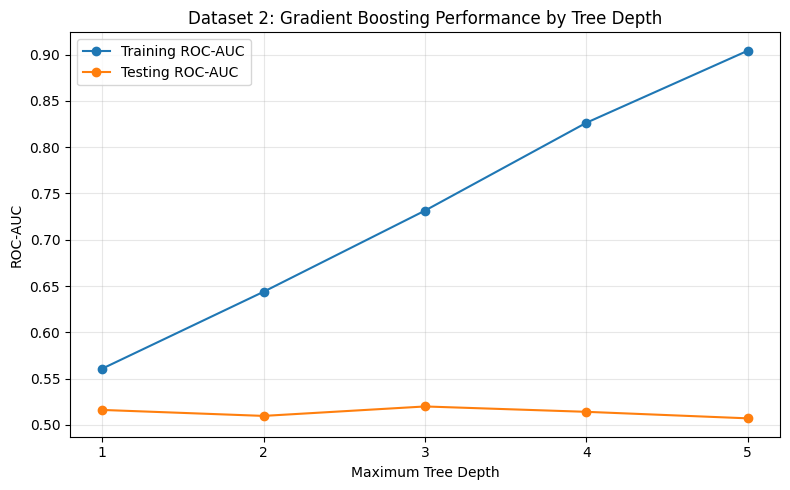

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(
    depth_results2_df["Max Depth"],
    depth_results2_df["Train ROC-AUC"],
    marker="o",
    label="Training ROC-AUC"
)
plt.plot(
    depth_results2_df["Max Depth"],
    depth_results2_df["Test ROC-AUC"],
    marker="o",
    label="Testing ROC-AUC"
)
plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC-AUC")
plt.title("Dataset 2: Gradient Boosting Performance by Tree Depth")
plt.xticks(depth_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Dataset 2 Conclusion

The performance of Gradient Boosting was not impressive on the Marketing and Product Performance dataset. In the beginning, the accuracy rate stood at 51.55%, while the ROC-AUC was 0.5111, and after tuning, the accuracy and ROC-AUC became 50.40% and 0.5129 respectively. In hyperparameter comparison, it was observed that increasing the learning rate, number of estimators, and tree depth increased the training performance, but at the same time led to heavy overfitting. Even though regularization helped a little bit, yet testing performance was almost the same as a random guess.

## Dataset 3: Synthetic B2B CRM & Marketing

The target variable is Active_Contract, representing whether a company currently has an active contract. Gradient Boosting will be used to classify companies based on annual revenue, marketing spend, days since last purchase, and total purchases during the previous year. The dataset will be divided into training and testing sets using an 80/20 stratified split. Feature scaling is not required because Gradient Boosting uses decision trees.

In [23]:
df3["Active_Contract"] = (df3["Contract_Status"] == "Active").astype(int)
features3 = [
    "Annual_Revenue (M₺)",
    "Marketing_Spend (K₺)",
    "Days_Since_Last_Purchase",
    "Total_Purchases_Last_Year"
]

X3 = df3[features3]
y3 = df3["Active_Contract"]
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.2, random_state=42, stratify=y3
)

print("Training:", X3_train.shape)
print("Testing:", X3_test.shape)
print("\nTarget Distribution:")
print(y3.value_counts())

Training: (587, 4)
Testing: (147, 4)

Target Distribution:
Active_Contract
1    528
0    206
Name: count, dtype: int64


### Initial Gradient Boosting Model

In [24]:
gb3 = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

gb3.fit(X3_train, y3_train)
y3_pred = gb3.predict(X3_test)
y3_prob = gb3.predict_proba(X3_test)[:, 1]

print("Gradient Boosting (100 Estimators, LR=0.1, Depth=3)")
print("Accuracy:", round(accuracy_score(y3_test, y3_pred), 4))
print("Precision:", round(precision_score(y3_test, y3_pred), 4))
print("Recall:", round(recall_score(y3_test, y3_pred), 4))
print("F1 Score:", round(f1_score(y3_test, y3_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, y3_prob), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y3_test, y3_pred))

Gradient Boosting (100 Estimators, LR=0.1, Depth=3)
Accuracy: 0.6531
Precision: 0.7037
Recall: 0.8962
F1 Score: 0.7884
ROC-AUC: 0.5066

Confusion Matrix:
[[ 1 40]
 [11 95]]


The initial Gradient Boosting model achieved 65.31% accuracy and a ROC-AUC of 0.5066, indicating limited predictive performance. Although recall reached 89.62%, the confusion matrix showed that the model correctly identified only 1 inactive contract while identifying 95 active contracts. This suggests that the model strongly favors the majority class. Compared with KNN from Week 8, Gradient Boosting achieved a higher ROC-AUC but lower accuracy. Overall, class imbalance and limited predictive relationships remain challenges for this dataset.

### Learning Rate and Number of Estimators

In [25]:
learning_rates = [0.01, 0.05, 0.1, 0.2]
estimators = [50, 100, 200]
lr_results3 = []

for lr in learning_rates:
    for n in estimators:
        model = GradientBoostingClassifier(
            n_estimators=n,
            learning_rate=lr,
            max_depth=3,
            random_state=42
        )

        model.fit(X3_train, y3_train)
        train_prob = model.predict_proba(X3_train)[:, 1]
        test_prob = model.predict_proba(X3_test)[:, 1]
        lr_results3.append({
            "Learning Rate": lr,
            "Estimators": n,
            "Train ROC-AUC": roc_auc_score(y3_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y3_test, test_prob)
        })

lr_results3_df = pd.DataFrame(lr_results3)
print(lr_results3_df.round(4).to_string(index=False))

 Learning Rate  Estimators  Train ROC-AUC  Test ROC-AUC
          0.01          50         0.6915        0.4573
          0.01         100         0.7255        0.4848
          0.01         200         0.7610        0.5221
          0.05          50         0.7772        0.5232
          0.05         100         0.8445        0.5305
          0.05         200         0.9282        0.4971
          0.10          50         0.8626        0.5346
          0.10         100         0.9322        0.5066
          0.10         200         0.9806        0.4770
          0.20          50         0.9173        0.5048
          0.20         100         0.9797        0.5002
          0.20         200         0.9982        0.4956


Changing the learning rate and number of estimators revealed substantial overfitting. The highest testing ROC-AUC of 0.5346 was achieved with a learning rate of 0.10 and 50 estimators. Increasing the learning rate to 0.20 with 200 estimators raised training ROC-AUC to 0.9982 but reduced testing ROC-AUC to 0.4956. These results indicate that increasing model complexity caused Gradient Boosting to learn patterns specific to the training data without improving its ability to predict contract status.

### Tree Depth Comparison

In [26]:
depth_values = [1, 2, 3, 4, 5]
depth_results3 = []

for depth in depth_values:
    model = GradientBoostingClassifier(
        n_estimators=50,
        learning_rate=0.1,
        max_depth=depth,
        random_state=42
    )

    model.fit(X3_train, y3_train)
    train_prob = model.predict_proba(X3_train)[:, 1]
    test_prob = model.predict_proba(X3_test)[:, 1]

    depth_results3.append({
        "Max Depth": depth,
        "Train ROC-AUC": roc_auc_score(y3_train, train_prob),
        "Test ROC-AUC": roc_auc_score(y3_test, test_prob)
    })

depth_results3_df = pd.DataFrame(depth_results3)
print(depth_results3_df.round(4).to_string(index=False))

 Max Depth  Train ROC-AUC  Test ROC-AUC
         1         0.6466        0.5456
         2         0.7418        0.5351
         3         0.8626        0.5346
         4         0.9283        0.5453
         5         0.9838        0.5067


The depth of trees played an important role in Gradient Boosting. Maximum depth equal to one gave the best value of testing ROC-AUC, which was 0.5456. Increasing tree depth improved training ROC-AUC while having no impact on testing ROC-AUC. Training ROC-AUC value at the depth 5 was equal to 0.9838, whereas testing ROC-AUC value was much lower at 0.5067. Overfitting is very significant here.

### Regularization Comparison

In [27]:
leaf_values = [1, 5, 10]
subsample_values = [0.7, 0.85, 1.0]
reg_results3 = []

for leaf in leaf_values:
    for sample in subsample_values:
        model = GradientBoostingClassifier(
            n_estimators=50,
            learning_rate=0.1,
            max_depth=1,
            min_samples_leaf=leaf,
            subsample=sample,
            random_state=42
        )

        model.fit(X3_train, y3_train)
        train_prob = model.predict_proba(X3_train)[:, 1]
        test_prob = model.predict_proba(X3_test)[:, 1]
        reg_results3.append({
            "Min Leaf": leaf,
            "Subsample": sample,
            "Train ROC-AUC": roc_auc_score(y3_train, train_prob),
            "Test ROC-AUC": roc_auc_score(y3_test, test_prob)
        })

reg_results3_df = pd.DataFrame(reg_results3)
print(reg_results3_df.round(4).to_string(index=False))

 Min Leaf  Subsample  Train ROC-AUC  Test ROC-AUC
        1       0.70         0.6726        0.5254
        1       0.85         0.6752        0.5492
        1       1.00         0.6466        0.5456
        5       0.70         0.6737        0.5207
        5       0.85         0.6755        0.5186
        5       1.00         0.6461        0.5490
       10       0.70         0.6713        0.5163
       10       0.85         0.6748        0.5235
       10       1.00         0.6471        0.5449


Regularization led to slight enhancements in the Gradient Boosting algorithm. The best ROC-AUC value for testing was recorded at 0.5492 using a minimum leaf size of 1 and subsampling of 0.85. Altering these parameters did not lead to consistent enhancement in the performance of the model but slightly decreased the discrepancy between testing and training. Regularization brought about minimal improvement in the model, and the model still performed poorly when it came to predicting active contract status.

### Gradient Boosting Hyperparameter Tuning

In [28]:
param_grid3 = {
    "n_estimators": [50, 100, 200],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [1, 2, 3],
    "min_samples_leaf": [1, 5],
    "subsample": [0.7, 0.85, 1.0]
}

grid3 = GridSearchCV(
    GradientBoostingClassifier(random_state=42),
    param_grid3,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid3.fit(X3_train, y3_train)
print("Best Parameters:", grid3.best_params_)
print("Best Cross-Validation ROC-AUC:", round(grid3.best_score_, 4))

best_gb3 = grid3.best_estimator_
y3_pred_tuned = best_gb3.predict(X3_test)
y3_prob_tuned = best_gb3.predict_proba(X3_test)[:, 1]

print("\nTuned Gradient Boosting Testing Results:")
print("Accuracy:", round(accuracy_score(y3_test, y3_pred_tuned), 4))
print("Precision:", round(precision_score(y3_test, y3_pred_tuned), 4))
print("Recall:", round(recall_score(y3_test, y3_pred_tuned), 4))
print("F1 Score:", round(f1_score(y3_test, y3_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y3_test, y3_prob_tuned), 4))
print("\nConfusion Matrix:")
print(confusion_matrix(y3_test, y3_pred_tuned))

Best Parameters: {'learning_rate': 0.1, 'max_depth': 1, 'min_samples_leaf': 5, 'n_estimators': 50, 'subsample': 0.7}
Best Cross-Validation ROC-AUC: 0.5291

Tuned Gradient Boosting Testing Results:
Accuracy: 0.7143
Precision: 0.7222
Recall: 0.9811
F1 Score: 0.832
ROC-AUC: 0.5207

Confusion Matrix:
[[  1  40]
 [  2 104]]


GridSearchCV identified a learning rate of 0.10, 50 estimators, a maximum tree depth of 1, a minimum leaf size of 5, and a subsample of 0.70 as the best parameters. The tuned model achieved 71.43% accuracy and a testing ROC-AUC of 0.5207, improving upon the initial model's results. Recall also increased to 98.11%. However, the confusion matrix showed that the model correctly identified only 1 inactive contract while identifying 104 active contracts. Despite improved accuracy and recall, the model continued to favor the majority class and demonstrated limited ability to distinguish active contracts from inactive contracts.

In [33]:
print("Dataset 3 Classification Report:")
print(classification_report(y3_test, y3_pred_tuned))

Dataset 3 Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.02      0.05        41
           1       0.72      0.98      0.83       106

    accuracy                           0.71       147
   macro avg       0.53      0.50      0.44       147
weighted avg       0.61      0.71      0.61       147



However, the tuned Gradient Boosting model demonstrated a performance of 71% accuracy but still had large differences among classes. For instance, Class 1 had a recall of 0.98 whereas Class 0 had a recall of 0.02, which suggests that the almost all inactive companies have been wrongly classified. Given that 72% of the total number of companies had active contracts, the accuracy level of the model has been somewhat lower than what would be predicted using the majority class.

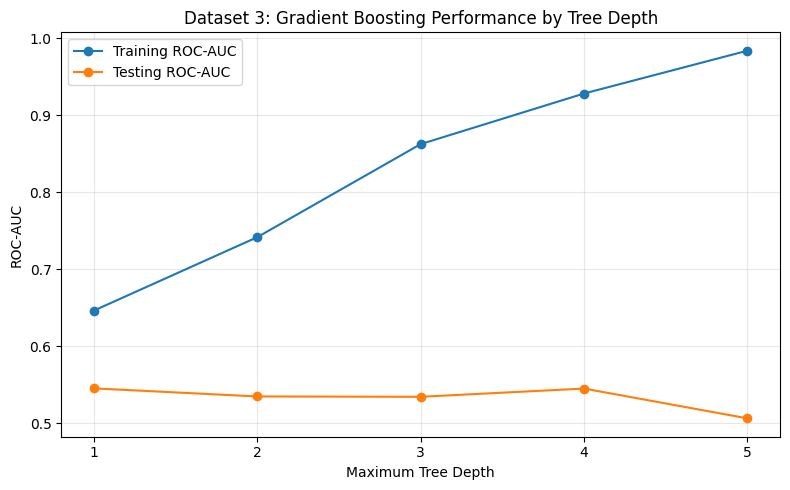

In [30]:
plt.figure(figsize=(8, 5))
plt.plot(
    depth_results3_df["Max Depth"],
    depth_results3_df["Train ROC-AUC"],
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    depth_results3_df["Max Depth"],
    depth_results3_df["Test ROC-AUC"],
    marker="o",
    label="Testing ROC-AUC"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("ROC-AUC")
plt.title("Dataset 3: Gradient Boosting Performance by Tree Depth")
plt.xticks(depth_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Demonstrates that training ROC-AUC increased substantially as tree depth increased, while testing ROC-AUC remained relatively low. A maximum depth of 1 achieved the highest testing ROC-AUC of 0.5456, while depth 5 produced a training ROC-AUC of 0.9838 and a testing ROC-AUC of 0.5067. This growing difference indicates substantial overfitting and suggests that simpler trees provide better generalization for this dataset.

### Dataset 3 Conclusion

The predictive performance of Gradient Boosting was poor on the Synthetic B2B CRM & Marketing data set. The first model gave an accuracy rate of 65.31% and ROC-AUC value of 0.5066, whereas the optimized model gave an accuracy of 71.43% and ROC-AUC value of 0.5207. In terms of comparison of hyperparameters, it is observed that with increase in the learning rate, number of estimators, and depth of trees, there is considerable overfitting. However, the optimization of model increased the accuracy and recall rate. Nonetheless, the model preferred the active contracts.

## Conclusion

Gradient Boosting was tested using three marketing datasets in order to investigate the ability of the algorithm in forecasting customer conversions, return on investment of marketing campaigns, and active contracts. The best performance was observed for the Digital Marketing Campaign dataset with a tuned ROC-AUC score of 0.7333. The scores of ROC-AUC for the Marketing and Product Performance and Synthetic B2B CRM & Marketing datasets were 0.5129 and 0.5207, respectively. Hyperparameters tuning proved that an increase of learning rates, number of estimators, and tree depth usually resulted in an improvement of training performance without a corresponding improvement in the testing performance which is the sign of overfitting. Shallow trees yielded better generalization whereas regularization was effective only marginally. In comparison with the KNN algorithm used in week 8, the ROC-AUC scores obtained by Gradient Boosting were higher for all three datasets but the predictions were still weak for the ROI of campaigns and active contracts.